[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ichristov/intermediate-fluid-mechanics/blob/main/Stokes_2nd_problem.ipynb)


# LEARNING OBJECTIVE

After exploring this notebook, you will be able to visualize the unsteady solution to Stokes' 2nd problem of the post-transient ("steady") oscillations of a plate/wall.

# PRELIMINARIES

[run the next cell to set up Python environment customizations and load packages]

In [6]:
# interactive plots setup
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

# sympy setup
import sympy as sp
sp.init_printing()
from sympy.vector import *

# plotting customizations
from matplotlib import colormaps, animation, rc
from matplotlib import pyplot as plt
size=16
params = {'legend.fontsize': 'large',
#          'figure.figsize': (20,8),
          'axes.labelsize': size,
          'axes.titlesize': size,
          'xtick.labelsize': size*0.875,
          'ytick.labelsize': size*0.875,
          'axes.titlepad': 25}
plt.rcParams.update(params)
%matplotlib inline

# numerics
import numpy as np
from scipy.optimize import root_scalar

# for Colab only: to save plots as files and download them
#from google.colab import files

## Credit

Initial version written by [Ivan C. Christov](http://christov.tmnt-lab.org), Purdue University.

# STOKES' 2nd PROBLEM

The problem of the post-transient ("steady") unidirectional flow caused by an oscillating plate was first considered by [G. G. Stokes](https://en.wikipedia.org/wiki/Sir_George_Stokes,_1st_Baronet) in his 1850 treatise "On the effect of the internal friction of fluids on the motion of pendulums" published in the _Transactions of the Cambridge Philosophical Society_ [(Stokes, 1850)](https://archive.org/details/b22464074/page/13/mode/2up) (pages 13&ndash;14, "art. 7").

## Visualization of the solution

The post-transient solution that we derived in class (see also Section 11.4 of _Incompressible Flow_ [(Panton, 2013)](https://doi.org/10.1002/9781118713075)) is
$$
    \frac{v_x}{V_0} (y,t) = e^{-\frac{y}{\sqrt{2\nu/\Omega}}} \sin\left(\Omega t - \frac{y}{\sqrt{2\nu/\Omega}} \right).
$$

We can now let ${v}_x^* = v_x/V_0$, $y^* = y/\sqrt{2\nu/\Omega}$, and $t^* = \Omega t$ be the dimensionless velocity, the dimensionless distance from the plate, and the dimensionless time, respectively. Then, the profile is
$$ 
    v_x^*(y^*,t^*) = e^{-y^*} \sin\left(t^* - y^*\right).
$$

This form of the solution has no free parameters, it is _universal_. However, it is unsteady, so we wish to see it at different instants of $t^*$ by making an animation. 

Keep in mind that $t^*=0$ is just some arbitrary timepoint, at which we've reset time, once the flow is the post-transient, periodic regime. That is, transients due to startup from rest took place for $t^*<0$. The transient itself is worked out in the [Stokes' 2nd problem transient](extras/Stokes_2nd_transient.ipynb) notebook.

Before animating the continuous evolution, let's first look at a static overlay of a few representative phases within one period.

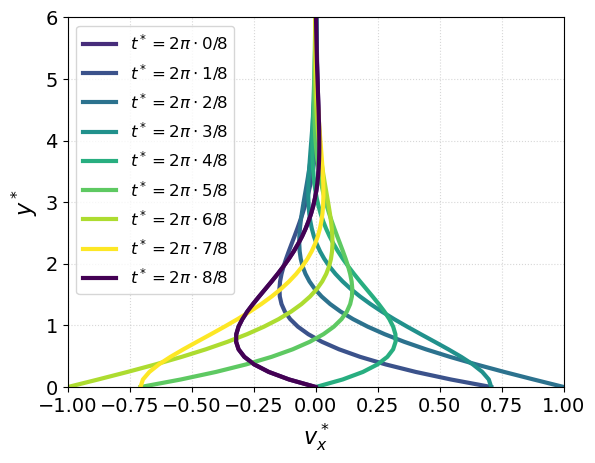

In [7]:
# define vertical extent of plot and grid
ymax = 6.0
y = np.linspace(0, ymax, endpoint=True)

# sequential colormap with gradient that looks nice, also try 'cool' or 'summer'
# https://matplotlib.org/stable/users/explain/colors/colormaps.html#sequential
cmap = colormaps['viridis']

# set up the figure and axis
fig, ax = plt.subplots()
ax.set_ylabel('$y^*$')
ax.set_ylim(0, ymax)
ax.set_xlabel('$v_x^*$')
ax.set_xlim(-1, 1)

ax.grid(alpha=0.5, linestyle='dotted')

ts = np.linspace(0, 2*np.pi, 9, endpoint=True)
for i in range(0, len(ts)):
    vx = np.exp(-y)*np.sin(ts[i]-y)
    randcol = cmap(ts[(i+1) % 9]/ts.max())  # argument from 0 to 1
    ax.plot(vx, y,
            linewidth=3, color=randcol, label=rf'$t^* = 2\pi\cdot{i}/8$')

ax.legend(loc='upper left');

We can also illustrate the solution as an animation.

In [8]:
# define vertical extent of plot and grid
ymax = 6.0
y = np.linspace(0, ymax, endpoint=True)

# set up the figure and axis
fig, ax = plt.subplots()
ax.set_ylabel('$y^*$')
ax.set_ylim(0, ymax)
ax.set_xlabel('$v_x^*$')
ax.set_xlim(-1, 1)
# if you want to move horizontal axis label to top so it doesn't clash with animation controls
# but fig.tight_layout() below also fixes this
# ax.xaxis.set_label_position('top')
# ax.xaxis.set_ticks_position('top')
plt.close()

# initialize plot and quiver objects with some dummy data (replaced in animation)
line, = ax.plot(0*y, y,
                linewidth=4, color='darkblue', label=r'$t^* = 2\pi\cdot 0.000$')
# add envelope of all curves
ax.plot(np.exp(-y), y,
        linewidth=2, linestyle='dashed', color='gray', label='envelope, $e^{-y^*}$')
ax.plot(-np.exp(-y), y,
        linewidth=2, linestyle='dashed', color='gray')
# skip every other data point to reduce number of arrows
quiv = ax.quiver(0*y[::2], y[::2], 0*y[::2], 0*y[::2],
                 scale=1., scale_units='xy', color='blue', zorder=2)
ax.legend(loc='upper right')

# number of animation frames; 40 frames over exactly one period,
# t* = 0 to 2*pi*39/40, so the animation loops seamlessly
numframes = 40
tmax = 2*np.pi

# animation function called sequentially by `FuncAnimation' below
def animate(t):
    # the t passed is actually the frame counter, not time
    # so it should be rescaled to get actual time as % of the frames
    # also shift it slightly so we don't divide by 0
    tt = 0.0 + t/numframes * tmax

    vx = np.exp(-y)*np.sin(tt-y)
    line.set_data(vx, y)
    # update the label, in multiples of 2*pi with 3 decimals, and redraw the legend
    line.set_label(rf'$t^* = 2\pi\cdot{tt/(2*np.pi):.3f}$')
    # plot arrows emanating only from the reference line, x-coord = 0
    quiv.set_UVC(vx[::2], 0*vx[::2])

    ax.legend(loc='upper right')
    ax.grid(alpha=0.5, linestyle='dotted')

    return (line, quiv,)

# lay out the figure once, so the axes don't shift by a pixel between frames
fig.tight_layout()

anim = animation.FuncAnimation(fig, animate,
                               frames=numframes, interval=100, blit=True)

In [9]:
# this is necessary to get the animation to work on Google's Colab
rc('animation', html='jshtml')
anim

In [10]:
# To save the animation, use something like
# anim.save(f"Stokes_2nd_prob_movie.mp4")

# or
# writer = animation.FFMpegWriter(fps=15, metadata=dict(artist='Me'), bitrate=1800)
# anim.save(f"Stokes_2nd_prob_movie.mp4", writer=writer)

## Discussion: the viscous oscillatory "boundary layer" thickness

From this interactive plot, we observe that the velocity variation is confined to an "oscillatory boundary layer" near the plate, decaying quickly away from the plate.

Let us calculate this "boundary layer thickness" by solving for the value of $y^*$ such that $v_x^*=0.01$ (equivalently, $y$ such that $v_x = 0.01V_0$, in dimensional form). The value $y^*$ represents the distance above the plate at which the velocity has decayed to a mere 1% of the plate's velocity.

However, $v_x^*$ is unsteady and depends on both $y^*$ and $t^*$. For definiteness, let us just pose the question for the _envelope_ of $v_x^*$. Since $-1 \le \sin(y^* - t^*)\le 1$, the envelope of $v_x^*$ is $e^{-y^*}$, which is the quantity that sets the amplitude of the velocity oscillations.

This can be done, in general, using [SciPy](https://docs.scipy.org/doc/scipy/reference/optimize.html#root-finding)'s nonlinear root-finding capabilities.

In [11]:
def eq_func(ystar):
    # define a function v_envelope(y*) - 0.01, which = 0 for the value
    # of y* = delta* that we seek as a solution; although for this function
    # you could've done this by hand, let's use scipy anyways ...
    return np.exp(-ystar) - 0.01

# eq_func changes sign between y* = 0 and y* = 10, so bracket the root there
sol = root_scalar(eq_func, bracket=[0, 10])
ystar_sol = sol.root
ystar_sol

In [12]:
# needed for the second expression below
ystar_sol*np.sqrt(2)

Therefore, the "boundary layer thickness" is $y^* = \delta^* \approx 4.6$. From the definition of $y^*$, we have
$$ 
    y = \delta \approx 4.6 \sqrt{\frac{2\nu}{\Omega}} \approx 6.5 \sqrt{\frac{\nu}{\Omega}}
$$
in dimensional form.

For air at 20&deg;C, the [kinematic viscosity](https://www.engineeringtoolbox.com/air-absolute-kinematic-viscosity-d_601.html) is $\nu \approx 15\times 10^{-6}$ m<sup>2</sup>/s. Considering a plate frequency of 1 Hz ($\Omega = 2\pi$ rad/s), we obtain $\delta \approx 1$ cm. Not small!


In [13]:
6.5*np.sqrt((15e-6)/(2*np.pi))

Similar to Stokes' 1st problem, this distance is proportional to $\sqrt{\nu}$. Unlike Stokes' 1st problem, this distance is independent of $t$. Also unlike Stokes' 1st problem, the plate's oscillation frequency $\Omega$ reduces the oscillatory boundary layer thickness. For fast plate motion, the fluid doesn't have time to "react" to the oscillations.

We can show this thickness on the velocity field plot:

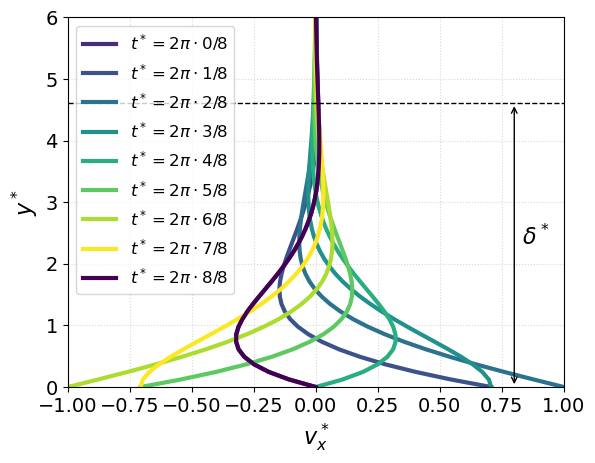

In [16]:
# define vertical extent of plot and grid
ymax = 6.0
y = np.linspace(0, ymax, endpoint=True)

# sequential colormap with gradient that looks nice, also try 'cool' or 'summer'
# https://matplotlib.org/stable/users/explain/colors/colormaps.html#sequential
cmap = colormaps['viridis']

# set up the figure and axis
fig, ax = plt.subplots()
ax.set_ylabel('$y^*$')
ax.set_ylim(0, ymax)
ax.set_xlabel('$v_x^*$')
ax.set_xlim(-1, 1)

ax.grid(alpha=0.5, linestyle='dotted')

ts = np.linspace(0, 2*np.pi, 9, endpoint=True)
for i in range(0, len(ts)):
    vx = np.exp(-y)*np.sin(ts[i]-y)
    randcol = cmap(ts[(i+1) % 9]/ts.max())  # argument from 0 to 1
    ax.plot(vx, y,
            linewidth=3, color=randcol, label=rf'$t^* = 2\pi\cdot{i}/8$')

ax.legend(loc='upper left')

ax.plot(np.linspace(-1, 1), ystar_sol*np.ones_like(np.linspace(-1, 1)),
        linewidth=1, color='black', linestyle='dashed')
# add nice arrow
ax.text(0.83, ystar_sol/2, r'$\delta^*$', fontdict={'size': 16})
ax.annotate("", (0.8, 0), (0.8, ystar_sol),
            arrowprops={'arrowstyle': '<->'});

# FURTHER EXPLORATION

In the animation above, there is also a clear _phase lag_ between the velocity (and direction) of fluid some distance above the plate and the velocity of/near/at the plate. It almost looks like "wave" is "propagating" up from the plate. It is not a true wave but it looks like one. We call it a [_kinematic wave_](https://www.linkedin.com/pulse/kinematic-waves-ivan-christov). 

On your own:
* Figure out the phase speed of the kinematic wave from the exact solution to the problem. (See also Panton, bottom of p. 230.)
* Compute the vorticity of this flow, and study how it evolves. 
    - How many nonzero components does the vorticity vector of such a flow have?
* Compute the viscous shear stress on the plate, and study how it evolves.
    - Does the maximum shear stress occur at the same $t^* = \Omega t$ values as the maximum velocity?
* Explore the viscoelastic counterpart of Stokes' second problem, for an Oldroyd-B fluid, worked out and verified in the viscoelastic-startup repository [(Christov, 2026)](https://github.com/ichristov/viscoelastic-startup). Its post-transient solution is worked out, at a level accessible to students, by [Hopkins & de Bruyn (2014)](https://doi.org/10.1139/cjp-2013-0334); see [Christov (2015)](https://arxiv.org/abs/1506.01470) for some corrections. How does the fluid's elasticity change the oscillatory boundary layer?


# REFERENCES

I. C. Christov, Comment on "The velocity field due to an oscillating plate in an Oldroyd-B fluid" by C.C. Hopkins and J.R. de Bruyn [Can. J. Phys. 92, 533 (2014)], _Can. J. Phys._ **93** (2015) 1651&ndash;1652. [doi:10.1139/cjp-2015-0374](https://doi.org/10.1139/cjp-2015-0374); [arXiv:1506.01470](https://arxiv.org/abs/1506.01470)

I. C. Christov, viscoelastic-startup: Verification and reproducibility of exact solutions for start-up flows of viscoelastic fluids (Jupyter notebooks), Zenodo, 2026. [doi:10.5281/zenodo.22930189](https://doi.org/10.5281/zenodo.22930189); [<img src="https://github.githubassets.com/images/icons/emoji/octocat.png" width="20" alt="Octocat"> GitHub](https://github.com/ichristov/viscoelastic-startup)

C. C. Hopkins, J. R. de Bruyn, The velocity field due to an oscillating plate in an Oldroyd-B fluid, _Can. J. Phys._ **92** (2014) 533&ndash;538. [doi:10.1139/cjp-2013-0334](https://doi.org/10.1139/cjp-2013-0334)

R. L. Panton, _Incompressible Flow_, 4th ed., Wiley, 2013. [doi:10.1002/9781118713075](https://doi.org/10.1002/9781118713075)

G. G. Stokes, On the effect of the internal friction of fluids on the motion of pendulums, _Trans. Camb. Philos. Soc._ **9** (Part II) (1850); reprint, Pitt Press, Cambridge, 1851, pp. 1&ndash;99. [Full text](https://archive.org/details/b22464074/page/92/mode/2up)